In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
# Load the Amazon dataset
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [3]:
# Example of data
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
# Check data structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [5]:
# Are there any null values?
df.isnull().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [6]:
## Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

## Generate a frequency table for the product category.
frequency_table = df['category'].value_counts()

In [7]:
frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [9]:
# Which are the top 5 most listed product categories?

top_5_products = frequency_table.head()

In [10]:
top_5_products

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

/var/folders/f3/4nxnf97x2z999nrldxm7ct1c0000gn/T/ipykernel_11486/4007410518.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=frequency_table.head().index, y=frequency_table.head().values, palette="Set3");


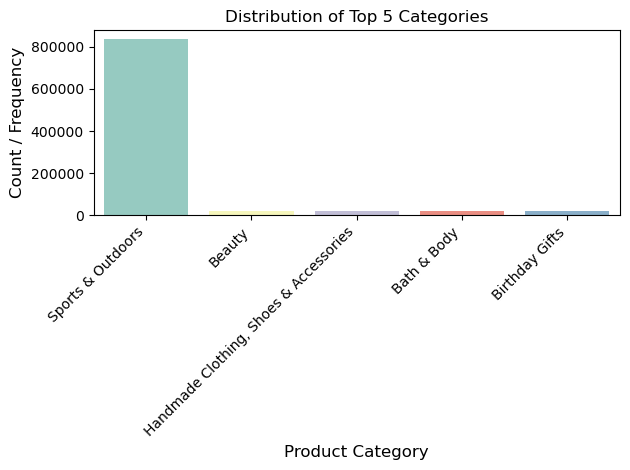

In [17]:
# Display the distribution of products across different categories using a bar chart. 
# If you face problems understanding the chart, do it for a subset of top categories.

# Plotting a bar chart using the values from the frequency table, with colors sourced from the "Set3" palette
sns.barplot(x=frequency_table.head().index, y=frequency_table.head().values, palette="Set3");

plt.xticks(rotation=45, ha="right")
plt.title(f"Distribution of Top 5 Categories")
plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Count / Frequency", fontsize=12)

plt.tight_layout()
plt.show()

In [23]:
counts = df['category'].value_counts()
counts

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

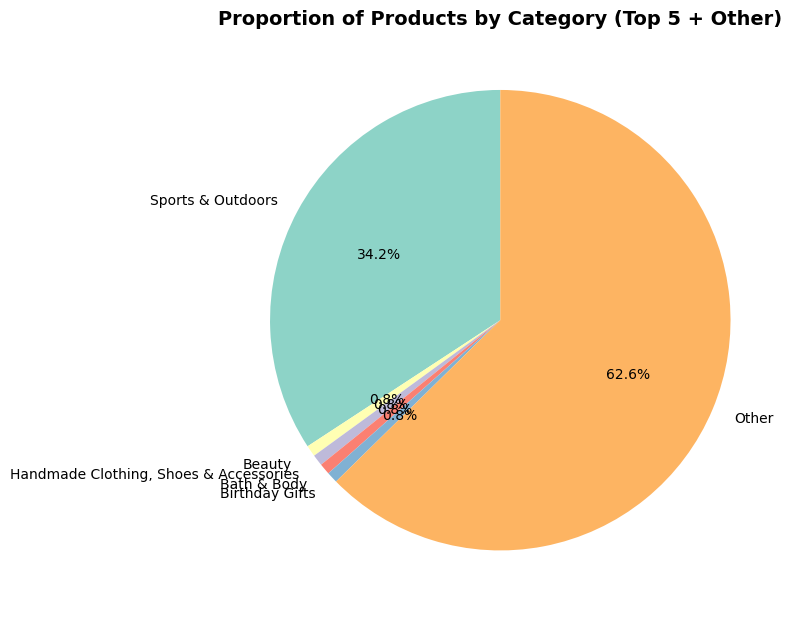

In [30]:
# For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

# 1. Get total counts per category
counts = df['category'].value_counts()

# 2. Extract top 5 categories and group the rest into 'Other'
top_5 = counts.iloc[:5]
other_count = pd.Series({'Other': counts.iloc[5:].sum()})

# 3. Combine them into one Series
category_summary = pd.concat([top_5, other_count])

# 4. Plot the cleaned pie chart
plt.figure(figsize=(8, 8))
category_summary.plot.pie(
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette("Set3"))

plt.ylabel('')  # Hides the ugly 'count' label on the y-axis
plt.title('Proportion of Products by Category (Top 5 + Other)',fontsize=14,fontweight='bold')
plt.tight_layout()
plt.show()

In [31]:
# Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?
# Calculate the mean, median, and mode for the price of products

df['price'].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [54]:
max_price = df['price'].max()
max_price
# Show the row where price equals the max price
df[df['price'] == df['price'].max()]

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
2008013,2259336,B091F5Y3CT,HB FBA Test Treadmill,0.0,0,100000.0,False,0,Sports & Outdoors


In [55]:
min_price = df['price'].min()
min_price
# Show the row where price equals the min price
df[df['price'] == df['price'].min()]

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
342871,367018,B07TYXW54L,Exercises with Resistance Loop Bands: 40+ Exer...,4.1,94,0.0,False,0,Sports & Outdoors
546823,589599,B003WL4O38,Operation Mincemeat: The True Spy Story that C...,4.5,5795,0.0,False,0,PC & Video Games
547321,590132,B005KKRRVK,Kensuke’s Kingdom,4.7,4565,0.0,False,0,PC & Video Games
547507,590332,B09WRXGQZL,"Faith, Hope and Carnage",4.7,546,0.0,False,0,PC & Video Games
794353,855945,B07T7L39TN,Never Split the Difference: Negotiating as if ...,4.6,39112,0.0,True,0,School & Educational Supplies
830446,905582,B00E3SYBWS,"Go for the Gold, Atalanta! (Myth-O-Mania Book 8)",4.7,190,0.0,False,0,Games & Game Accessories
830795,905932,B0BJQQZ79H,Battle of the Fang: Space Marine Battles: Warh...,4.6,166,0.0,False,0,Games & Game Accessories
833556,908772,B07YGP8442,100 Years of Leeds United,4.8,1349,0.0,False,0,Games & Game Accessories
836136,911439,B0BLFPRMZH,"Dungeons & Guardians: Battleborne, Book III",4.7,2421,0.0,False,0,Games & Game Accessories
1025782,1134431,B0BL8LQCHZ,"4 in 1 Bundle Off the Grid Survival Book, Prep...",4.3,5,0.0,False,0,Sports & Outdoors


In [61]:
# After investigation, made a decision to drop products with $0.00 price since this is skewing the data
df_clean = df[df['price'] > 0]
min_price = df_clean['price'].min()
min_price

0.01

In [60]:
mean_price = df_clean['price'].mean()
mean_price

np.float64(89.24453985892305)

In [62]:
mode_price = df_clean['price'].mode()[0]
mode_price

np.float64(9.99)

In [38]:
# What's the average price point of products listed? How does this compare with the most common price point (mode)?

# The average price is $89.20 which is much higher than the most common price of $9.99

In [63]:
# Determine the variance, standard deviation, range, and interquartile range for product price.

variance = df_clean['price'].var()
std = df_clean['price'].std()
minimum = df_clean['price'].min()
maximum =  df_clean['price'].max()
price_range = maximum - minimum
quantiles_price = df_clean['price'].quantile([0.25, 0.5, 0.75])

In [46]:
variance
std
minimum
maximum
price_range
quantiles_price

0.25     9.99
0.50    19.09
0.75    45.99
Name: price, dtype: float64

In [47]:
# How varied are the product prices? Are there any indicators of a significant spread in prices?

# Most, as in 75% of prices are under $45.99. Because of some outliers with very high prices, the data is skewed to the left.

<Axes: xlabel='price', ylabel='Count'>

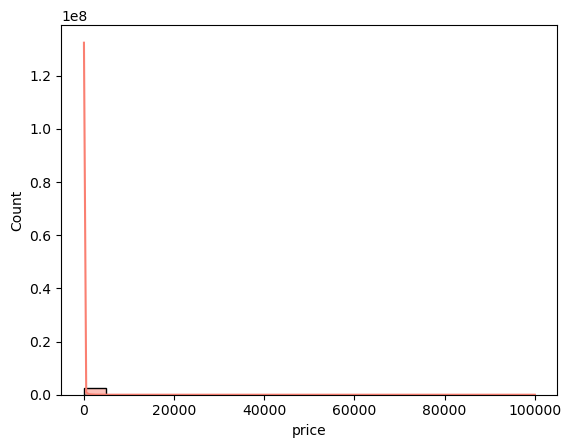

In [64]:
# Is there a specific price range where most products fall? 
# Plot a histogram to visualize the distribution of product prices. 
# If its hard to read these diagrams, think why this is, and explain how it could be solved.

sns.histplot(df_clean['price'], kde=True, bins=20, color="salmon")

# The distribution of the product prices is difficult to see because of the huge range in product prices.
# A better way would be to group the prices into price categories and display the data using a bar chart.

<Axes: ylabel='price'>

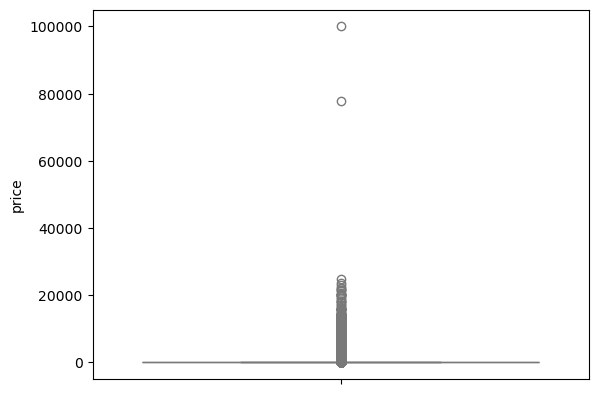

In [66]:
# Are there products that are priced significantly higher than the rest? 
# Use a box plot to showcase the spread and potential outliers in product pricing.

sns.boxplot(data = df_clean['price'], color="lightblue")

# Yes, there appear to be 2 high value products of around $100,000 and just under $800,000

In [69]:
# Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

# Calculate the mean, median, and mode for the rating of products.

df_clean['stars'].describe()

count    2.443631e+06
mean     2.152817e+00
std      2.194863e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64

In [70]:
#How do customers generally rate products? Is there a common trend?

# This tells me that there is a data quality issue because over 50% have 0 ratings. 
# For the products that do have ratings, 75% of them have 4.4 or higher rating. 
# The mean is not an accurate reflection of the average customer score because the many 0 ratings are pulling it down.

In [83]:
# Determine the variance, standard deviation, and interquartile range for product rating.
# Are the ratings consistent, or is there a wide variation in customer feedback?

rating_variance = df_clean['stars'].var()
rating_std = df_clean['stars'].std()
rating_min = df_clean['stars'].min()
rating_max =  df_clean['stars'].max()
quantiles_rating = df_clean['stars'].quantile([0.25, 0.5, 0.75])
rating_range = rating_max - rating_min

In [86]:
rating_variance
rating_std
rating_min
rating_max
rating_range
quantiles_rating

# The ratings are consistently between 4.0 and 5.0

0.25    0.0
0.50    0.0
0.75    4.4
Name: stars, dtype: float64

In [93]:
# Calculate the skewness and kurtosis for the rating column.
# Are the ratings normally distributed, or do they lean towards higher or lower values?
skewness_rating = df_clean['stars'].skew()
kurtosis_rating = df_clean['stars'].kurtosis()

skewness_rating
# Positive indicates it is right skewed, i.e there are more higher rated products

np.float64(0.0812237493707506)

In [94]:
kurtosis_rating
# An extremely low kurtosis rating means it is very flat in the middle with two peaks on either end, 1 around 0 and the other between 4 and 5


np.float64(-1.9260034791941232)

<Axes: xlabel='stars', ylabel='Count'>

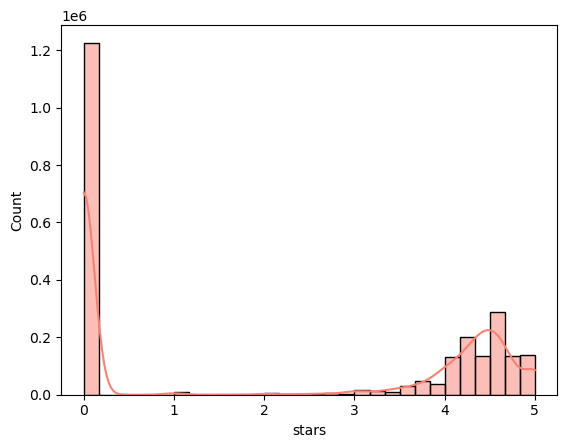

In [96]:
# Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?
sns.histplot(df['stars'], kde=True, bins=30, color="salmon")

# 0 is the most common with over 1.2million products having a 0 rating. After that, most products are scored around 4.5 stars.